# Hourly base data

This notebook builds the **continuous hourly Bitcoin series** that every other notebook should start from. It does no windowing, no train/test split and no scaling: those are model decisions and stay out of the base data (scaling is still pending).

Output: `data/btc_hourly.csv.gz`, one row per hour from 2018-01-01, with columns `Open, High, Low, Close, Volume, Return, filled_minutes, no_trade`.

**Structure**

1. Settings and raw data.
2. Minute-level checks, and the hidden gaps.
3. Hourly candles.
4. Time cut: keep 2018 onwards.
5. Hidden gaps after the cut.
6. Final checks.
7. Export.

## 1. Settings and raw data

The source is the Kaggle dataset `mczielinski/bitcoin-historical-data` (1-minute Bitstamp candles, timestamps in UTC). Kaggle adds a new version every day, so `dataset_download` without a version would give a slightly different file each time. **The version is pinned** so that the base data stays frozen and everybody works on the same hours. Change it only on purpose, and announce it.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub

KAGGLE_DATASET = "mczielinski/bitcoin-historical-data/versions/746"   # pinned version (ends 8 Oct 2026)
DATA_START = "2018-01-01"       # first hour kept, see section 4
OUTAGE_MIN_MINUTES = 60         # a run of filled minutes at least this long is listed as an outage
OUTPUT_PATH = os.path.join("data", "btc_hourly.csv.gz")

In [2]:
path = kagglehub.dataset_download(KAGGLE_DATASET)
raw = pd.read_csv(os.path.join(path, "btcusd_1-min_data.csv"))
raw.index = pd.to_datetime(raw.pop("Timestamp"), unit="s")
raw.index.name = "Timestamp"

print(f"{len(raw):,} minutes   {raw.index[0]} -> {raw.index[-1]}")
raw.head()

7,767,566 minutes   2012-01-01 00:01:00 -> 2026-10-08 03:26:00


,Open,High,Low,Close,Volume
Timestamp,,,,,
2012-01-01 00:01:00,4.58,4.58,4.58,4.58,0.0
2012-01-01 00:02:00,4.58,4.58,4.58,4.58,0.0
2012-01-01 00:03:00,4.58,4.58,4.58,4.58,0.0
2012-01-01 00:04:00,4.58,4.58,4.58,4.58,0.0
2012-01-01 00:05:00,4.58,4.58,4.58,4.58,0.0


## 2. Minute-level checks, and the hidden gaps

First the obvious problems: order, duplicates, missing values and missing minutes.

In [3]:
full_grid = pd.date_range(raw.index[0], raw.index[-1], freq="min")

print("Sorted by time:     ", raw.index.is_monotonic_increasing)
print("Duplicated minutes: ", raw.index.duplicated().sum())
print("Missing values:     ", int(raw.isna().sum().sum()))
print("Missing minutes:    ", len(full_grid.difference(raw.index)), f"of {len(full_grid):,}")

Sorted by time:      True
Duplicated minutes:  0
Missing values:      0
Missing minutes:     0 of 7,767,566


Not a single minute is missing, even in 2012, when Bitcoin traded only a few times per hour. That is because **the dataset fills its gaps instead of leaving them out**: a minute without trades is written as a candle with zero volume whose Open, High, Low and Close all repeat the previous close. These minutes look like real data, so `dropna()` or a "missing minutes" check never finds them. They are the hidden gaps.

The next cell checks that this is the case: every zero-volume minute should be flat and sit exactly at the previous close. Those minutes are marked as `filled`.

In [4]:
no_volume = raw["Volume"] == 0
flat = raw[["Open", "High", "Low"]].eq(raw["Close"], axis=0).all(axis=1)
carried = raw["Close"].eq(raw["Close"].shift())
filled = no_volume & flat & carried

print(f"Minutes with zero volume:                    {no_volume.sum():,} ({no_volume.mean():.1%} of all minutes)")
print(f"... flat and at the previous close (filled): {filled.sum():,} ({filled.sum() / no_volume.sum():.2%} of them)")
print(f"Minutes with volume but flagged as filled:   {(filled & ~no_volume).sum()}")

Minutes with zero volume:                    1,312,416 (16.9% of all minutes)
... flat and at the previous close (filled): 1,312,415 (100.00% of them)
Minutes with volume but flagged as filled:   0


All zero-volume minutes are filled minutes (the only exception is the very first minute of the file, which has no previous close to compare with). So **zero volume is a reliable marker of "no trade, price carried forward"**. Sections 4 and 5 use it to measure how much of each year is made up.

## 3. Hourly candles

The minutes are aggregated into hourly candles. Unlike `data-preparation.ipynb`, there is **no `dropna()`**: an empty hour would silently disappear and two hours that are not consecutive would end up next to each other. Instead each hour keeps two counters:

- `n_minutes`: how many minutes the hour has (should be 60).
- `filled_minutes`: how many of them are filled minutes (0 = fully traded, 60 = no trade at all).

In [5]:
hourly = raw.resample("h").agg({"Open": "first", "High": "max", "Low": "min", "Close": "last", "Volume": "sum"})
hourly["n_minutes"] = raw["Close"].resample("h").count()
hourly["filled_minutes"] = filled.resample("h").sum()

incomplete = hourly[hourly["n_minutes"] < 60]
print(f"{len(hourly):,} hours, of which empty: {(hourly['n_minutes'] == 0).sum()}, incomplete: {len(incomplete)}")
incomplete[["n_minutes"]]

129,460 hours, of which empty: 0, incomplete: 2


,n_minutes
Timestamp,
2012-01-01 00:00:00,59
2026-10-08 03:00:00,27


The only incomplete hours are the first one (the file starts at 00:01) and the last one, which was still in progress when the file was downloaded. The last hour matters: its Close is not the close of the hour, so its return would be wrong. Both edge hours are removed. An incomplete hour anywhere else would mean a real hole in the file, so the cell stops if it finds one.

The hourly return is computed **before** the time cut, so the first hour of 2018 also has a return (it uses the close of 31 Dec 2017, 23:00). `Return` is a simple return as a fraction (0.004 = +0.4%), the same definition as `data-preparation.ipynb`.

In [6]:
edges = {hourly.index[0], hourly.index[-1]}
assert set(incomplete.index) <= edges, "there is an incomplete hour in the middle of the series"

hourly = hourly.drop(incomplete.index).drop(columns="n_minutes")
hourly["Return"] = hourly["Close"].pct_change()
hourly["no_trade"] = hourly["filled_minutes"] == 60

print(f"{len(hourly):,} complete hours   {hourly.index[0]} -> {hourly.index[-1]}")

129,458 complete hours   2012-01-01 01:00:00 -> 2026-10-08 02:00:00


## 4. Time cut: keep 2018 onwards

The file starts in 2012, but the first years belong to a very different market. The table describes each year:

- `mean_abs_return_%`: average size of an hourly move.
- `share_zero_return_hours`: hours with exactly 0% change.
- `share_filled_minutes`: minutes without any trade (see section 2).
- `no_trade_hours`: hours without a single trade.
- `price_change_%`: change of the price from the first to the last hour of the year.

In [7]:
years = hourly.index.year
close_by_year = hourly["Close"].groupby(years)
yearly = pd.DataFrame({
    "mean_abs_return_%": hourly["Return"].abs().groupby(years).mean() * 100,
    "share_zero_return_hours": (hourly["Return"] == 0).groupby(years).mean(),
    "share_filled_minutes": filled.groupby(filled.index.year).mean(),
    "no_trade_hours": hourly["no_trade"].groupby(years).sum(),
    "price_change_%": (close_by_year.last() / close_by_year.first() - 1) * 100,
})
yearly.index.name = "year"
yearly.round(3)

,mean_abs_return_%,share_zero_return_hours,share_filled_minutes,no_trade_hours,price_change_%
year,,,,,
2012,0.581,0.485,0.949,3282,189.083
2013,0.920,0.051,0.392,123,5428.701
2014,0.568,0.009,0.242,2,-56.564
2015,0.422,0.022,0.291,107,34.796
2016,0.281,0.014,0.332,0,124.189
2017,0.710,0.003,0.080,0,1335.961
2018,0.574,0.001,0.038,0,-72.980
2019,0.412,0.000,0.033,0,94.063
2020,0.436,0.001,0.015,4,305.494


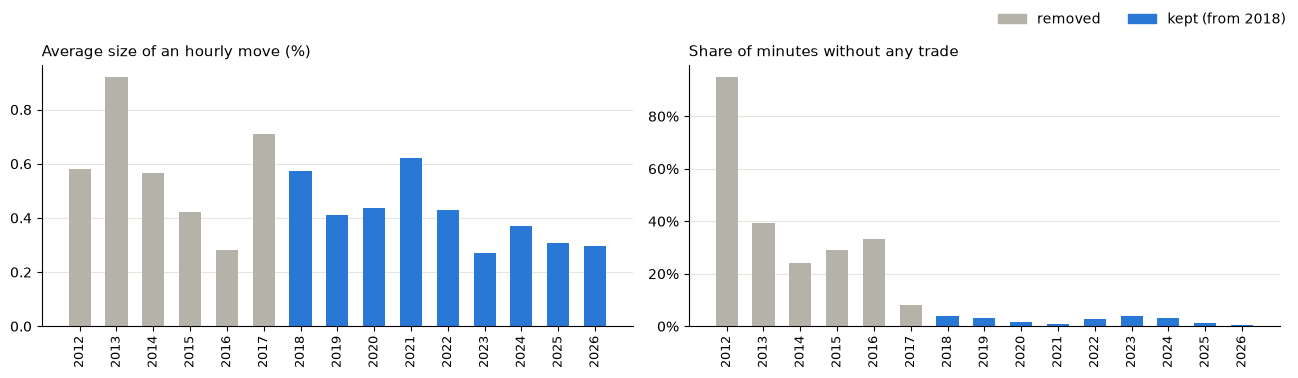

In [8]:
KEPT, DROPPED = "#2a78d6", "#b4b2a9"
colors = [KEPT if y >= pd.Timestamp(DATA_START).year else DROPPED for y in yearly.index]

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
panels = [("mean_abs_return_%", "Average size of an hourly move (%)"),
          ("share_filled_minutes", "Share of minutes without any trade")]
for ax, (col, title) in zip(axes, panels):
    ax.bar(yearly.index.astype(str), yearly[col], color=colors, width=0.6)
    ax.set_title(title, loc="left", fontsize=11)
    ax.tick_params(axis="x", labelrotation=90, labelsize=9)
    ax.grid(axis="y", color="#e5e4df", linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
axes[1].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=DROPPED), plt.Rectangle((0, 0), 1, 1, color=KEPT)],
           labels=["removed", f"kept (from {DATA_START[:4]})"], loc="upper right", frameon=False, ncol=2)
plt.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()

**Decision: keep only the hours from 1 Jan 2018.** The reasons are the ones given in version 2 of the models (`bitcoin-models-2018-2026.ipynb`, decision b), now measured directly on the hourly data:

- **2012–2016 is mostly made-up data.** In 2012, 95% of the minutes have no trade and about half of the hours show exactly 0% change because the price was carried forward. From 2013 to 2016, between a quarter and 40% of the minutes still have no trade, against 1–4% since 2018. These zeros are not calm markets: they are missing data in disguise.
- **The size of the moves was different.** 2012–2013 hourly moves are 2–3× larger than in recent years (0.6–0.9% against ~0.3%). A model that learns from them expects far too much movement.
- **2017 was a one-off bubble** (+1,336% in the year; version 2 counted 62% up days).

This was not only assumed, it was tested. Section 8 of version 2 trained the same models from different start years and scored them on the validation block:

- For the 24 hourly returns the start year makes no measurable difference (there is nothing to learn, so the training period cannot matter).
- For the volatility target, which *is* predictable, the early years clearly hurt: R² 0.29 when training from 2012 and 0.24 from 2014, against 0.41 from 2017 or 2018.
- 2017 and 2018 gave the same result (0.406 vs 0.409). 2018 is chosen because the later notebooks (version 3, its extensions and `course-methods.ipynb`) already use it, so the base data matches them, and because it leaves the 2017 bubble out.

Starting in 2018 still leaves almost 9 years of hourly data, with two bear markets (2018, 2022) and two bull markets (2020–2021, 2023–2024).

Note for the model notebooks: a 168-hour input window needs one week of history, so the first full window ends on 7 Jan 2018. Version 2 does the same ("the whole input week lies in 2018 or later").

In [9]:
rows_before = len(hourly)
hourly = hourly.loc[DATA_START:]

print(f"Removed {rows_before - len(hourly):,} hours before {DATA_START}")
print(f"Kept    {len(hourly):,} hours   {hourly.index[0]} -> {hourly.index[-1]}")

Removed 52,607 hours before 2018-01-01
Kept    76,851 hours   2018-01-01 00:00:00 -> 2026-10-08 02:00:00


## 5. Hidden gaps after the cut

After the cut, filled minutes are rare, but they still exist. Most of them are single quiet minutes. Longer runs are exchange outages: the price is frozen for an hour or more, and the move that happened meanwhile shows up all at once in the first hour after the outage. The cell groups consecutive filled minutes into runs and lists the long ones.

In [10]:
kept_filled = filled.loc[hourly.index[0]:hourly.index[-1] + pd.Timedelta(minutes=59)]

run_id = (kept_filled != kept_filled.shift()).cumsum()[kept_filled]
runs = (kept_filled[kept_filled].index.to_series()
        .groupby(run_id.values).agg(start="first", end="last", minutes="size"))
outages = runs[runs["minutes"] >= OUTAGE_MIN_MINUTES].sort_values("start").reset_index(drop=True)

print(f"Filled minutes since {DATA_START}: {kept_filled.sum():,} ({kept_filled.mean():.2%}) in {len(runs):,} runs")
print(f"Median run length: {runs['minutes'].median():.0f} minute(s); runs of {OUTAGE_MIN_MINUTES}+ minutes: {len(outages)}")
outages

Filled minutes since 2018-01-01: 108,653 (2.36%) in 90,689 runs
Median run length: 1 minute(s); runs of 60+ minutes: 15


,start,end,minutes
0,2019-07-25 09:17:00,2019-07-25 10:28:00,72
1,2020-04-25 19:58:00,2020-04-26 00:44:00,287
2,2020-08-26 10:04:00,2020-08-26 11:51:00,108
3,2021-04-14 08:02:00,2021-04-14 09:38:00,97
4,2021-10-20 08:02:00,2021-10-20 09:03:00,62
5,2022-01-05 08:02:00,2022-01-05 10:26:00,145
6,2022-05-11 08:04:00,2022-05-11 09:13:00,70
7,2022-07-13 10:57:00,2022-07-13 12:16:00,80
8,2022-07-27 08:02:00,2022-07-27 09:08:00,67
9,2023-03-23 10:04:00,2023-03-23 11:53:00,110


In [11]:
zero_ret = hourly["Return"] == 0
print(f"Hours without any trade (no_trade):   {hourly['no_trade'].sum()}")
print(f"Hours with exactly 0% change:         {zero_ret.sum()}"
      f"  (of which half or more of the minutes are filled: {(zero_ret & (hourly['filled_minutes'] >= 30)).sum()})")
print(f"Hours with at least one filled minute: {(hourly['filled_minutes'] > 0).sum():,} ({(hourly['filled_minutes'] > 0).mean():.1%})")

hourly.loc[hourly["no_trade"], ["Close", "Volume", "Return", "filled_minutes"]]

Hours without any trade (no_trade):   10
Hours with exactly 0% change:         149  (of which half or more of the minutes are filled: 11)
Hours with at least one filled minute: 28,381 (36.9%)


,Close,Volume,Return,filled_minutes
Timestamp,,,,
2020-04-25 20:00:00,7547.56,0.0,0.0,60
2020-04-25 21:00:00,7547.56,0.0,0.0,60
2020-04-25 22:00:00,7547.56,0.0,0.0,60
2020-04-25 23:00:00,7547.56,0.0,0.0,60
2022-01-05 09:00:00,46414.22,0.0,0.0,60
2022-07-13 11:00:00,19772.52,0.0,0.0,60
2023-07-03 12:00:00,30624.00,0.0,0.0,60
2024-12-07 02:00:00,100324.00,0.0,0.0,60
2024-12-07 03:00:00,100324.00,0.0,0.0,60


**Decision: keep these hours, but flag them.** They are a tiny fraction of the series, and removing them would break the continuous hourly grid that the 168-hour windows rely on (a window would then join hours that are not consecutive, the same problem as `dropna()`). Instead the export keeps two columns so that each model notebook can decide what to do:

- `filled_minutes` (0–60): how much of the hour is carried-forward price.
- `no_trade` (True/False): the hour had no trade at all, so its 0% return is not real.

A model can, for example, drop the windows whose target hours contain a `no_trade` hour, or give them a lower weight.

## 6. Final checks

The checks stop the notebook if any of these is false:

- The index is unique, sorted and moves exactly 1 hour at a time (no hidden holes).
- There are no missing values.
- Every candle is consistent: Low ≤ Open, Close ≤ High.
- Zero volume and `no_trade` mark exactly the same hours.

The last table lists the extreme hours (moves above 10%). The data-quality check of 18 Oct (see README) traced them to real events, such as the COVID crash of March 2020 and the crash of 19 May 2021, not to data errors. They stay in the data.

In [12]:
step = hourly.index.to_series().diff().dropna()
assert hourly.index.is_unique and hourly.index.is_monotonic_increasing
assert (step == pd.Timedelta(hours=1)).all(), "the hourly grid has holes"
assert hourly.notna().all().all(), "missing values"
assert (hourly["Low"] <= hourly[["Open", "Close"]].min(axis=1)).all()
assert (hourly["High"] >= hourly[["Open", "Close"]].max(axis=1)).all()
assert ((hourly["Volume"] == 0) == hourly["no_trade"]).all()
print("All checks passed:", f"{len(hourly):,} consecutive hours, no missing values")

extreme = hourly.loc[hourly["Return"].abs() > 0.10, ["Open", "Close", "Volume", "Return"]]
print(f"\nHours with a move above 10%: {len(extreme)}")
extreme

All checks passed: 76,851 consecutive hours, no missing values

Hours with a move above 10%: 9


,Open,Close,Volume,Return
Timestamp,,,,
2018-04-12 11:00:00,6935.90,7725.77,6147.111395,0.113971
2019-04-02 04:00:00,4174.83,4671.75,3798.250505,0.118465
2020-03-12 10:00:00,7342.49,6334.44,6856.299515,-0.137290
2020-03-12 23:00:00,5798.25,4841.67,8051.447101,-0.165484
2020-03-13 01:00:00,4671.14,4111.78,2209.176426,-0.119791
2020-03-13 02:00:00,4115.92,5049.75,5532.585803,0.228118
2020-03-15 21:00:00,5180.00,5942.09,3288.327897,0.147350
2021-01-29 08:00:00,32330.17,36314.60,2328.663515,0.123242
2021-05-19 12:00:00,38680.95,33885.78,2864.455412,-0.123956


## 7. Export

The hourly series is saved as a compressed CSV (the format of the other files in `data/`). Prices and volume are **not scaled**. The file is then read back to check that it round-trips.

In [13]:
columns = ["Open", "High", "Low", "Close", "Volume", "Return", "filled_minutes", "no_trade"]
os.makedirs(os.path.dirname(OUTPUT_PATH), exist_ok=True)
hourly[columns].to_csv(OUTPUT_PATH)

check = pd.read_csv(OUTPUT_PATH, index_col="Timestamp", parse_dates=True)
pd.testing.assert_frame_equal(check, hourly[columns], check_freq=False, check_exact=False,
                              check_index_type=False)   # same dates, only the time resolution differs
print(f"Saved {OUTPUT_PATH} ({os.path.getsize(OUTPUT_PATH) / 1e6:.1f} MB), {len(check):,} rows")
check.head()

Saved data\btc_hourly.csv.gz (2.6 MB), 76,851 rows


,Open,High,Low,Close,Volume,Return,filled_minutes,no_trade
Timestamp,,,,,,,,
2018-01-01 00:00:00,13880.00,13906.37,13600.26,13668.52,275.555024,-0.015236,0,False
2018-01-01 01:00:00,13635.06,13704.42,13312.94,13355.00,393.344524,-0.022937,0,False
2018-01-01 02:00:00,13355.00,13536.88,13302.02,13429.08,194.327902,0.005547,0,False
2018-01-01 03:00:00,13407.98,13640.00,13321.90,13481.73,317.537375,0.003921,1,False
2018-01-01 04:00:00,13481.73,13699.14,13372.41,13697.00,457.691397,0.015968,0,False


To load the data in another notebook:

```python
import pandas as pd

hourly = pd.read_csv("data/btc_hourly.csv.gz", index_col="Timestamp", parse_dates=True)
```